# Context-dependent remapping

Reproduces Fig. 3 (Sec. 2.5): between-context similarity decaying with context
separation, and the ratemaps at $s = 0$ and $s = 5$ showing that the grid structure
survives while its absolute phase shifts.

A scalar context enters exactly as the spatial coordinates do,
$p(x, y, s) = e^{xG_x + yG_y + sG_s}p_0$. This notebook is the conjunctive case: the
spatial generators are **metric-preserving** (roots of unity, so grids) while the context
generator is **similarity-preserving** (Gaussian spectrum, so smooth decorrelation).
There is no metric to preserve on a non-spatial variable — only similarity.

**Between-context similarity does not depend on position.** Because $G_s$ commutes with
$G_x$ and $G_y$ and all three are skew-symmetric, the spatial part cancels exactly:

$$
p(x,y,s_1)^\top p(x,y,s_2) = p_0^\top e^{-(xG_x+yG_y+s_1G_s)}e^{xG_x+yG_y+s_2G_s}p_0
  = p_0^\top e^{\Delta s\,G_s}p_0 = C(\Delta s)
$$

which is Eq. 5. The vertical scatter in the figure below is therefore **not** real
spread across the arena — it is ratemap binning error. The last cell shows the
unbinned quantity is constant across position to float32 precision.

**Parameters.** $M = 3$ and $s: 0 \to 5$ are Fig. 3; the $[0, 5]$ context range and the
$20 \times 20$ spatial domain are Appendix A. The original notebook used a $[-7.5, 7.5]$
arena and carried an unused `N = 60`.

As in `02_place_cells`, the Gaussian context spectrum in `data/parameters/sigma_C_pc.pt`
cannot be reconstructed without its seed, which was never recorded, so this notebook
draws an equivalent seeded one. The roots-of-unity spatial spectrum _is_ reconstructible
exactly and is built from source.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

import expmap
from expmap.analysis import batch_inference, compute_ratemaps
from expmap.generators import (
    block_diag_skew,
    build_generators_with_context,
    gaussian_eigenvalues,
    roots_of_unity_eigenvalues,
)
from expmap.linalg import random_orthogonal_matrix, starting_state
from expmap.model import RemappingModel
from expmap.plotting import ratemap_collage
from expmap.simulation import generate_uniform_positions

# Figure parameters. M = 3 and the s = 0 -> 5 shift are Fig. 3; the 20 x 20 spatial
# domain and the [0, 5] context range are Appendix A. SEED fixes the context spectrum,
# the mixing matrix R and the position sampling.
M = 3
N_COPIES = 50  # N = 2 * M * n_copies = 300
CONTEXT_SCALE = np.sqrt(2)
ARENA_SIZE = 10
BINS = 32
BATCH_SIZE, BATCHES = 50, 500
CONTEXT_VALS = np.linspace(0, 5, 20)
SEED = 0

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman"]

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

In [2]:
N = 2 * M * N_COPIES

# Spatial: roots of unity on the unit ring, so the spatial code is metric-preserving.
phi = roots_of_unity_eigenvalues(M, N_COPIES)
sigma_x = block_diag_skew(np.cos(phi))
sigma_y = block_diag_skew(np.sin(phi))

# Context: Gaussian spectrum, so between-context similarity decays smoothly (Sec. 2.5,
# sampling derivation in App. I). There is no metric to preserve on a non-spatial axis.
ev_s = gaussian_eigenvalues(N, scale=CONTEXT_SCALE, seed=SEED)
sigma_s = block_diag_skew(ev_s)

R = random_orthogonal_matrix(N, seed=SEED)
p0 = starting_state(R)
Gx, Gy, Gs = build_generators_with_context(sigma_x, sigma_y, sigma_s, R)

model = RemappingModel(Gx, Gy, Gs)

# Gs must be built "in the canonical way": skew-symmetric and commuting with the spatial
# generators. That is what makes the spatial part cancel out of Eq. 5.
for name, G in [("Gx", Gx), ("Gy", Gy), ("Gs", Gs)]:
    assert torch.allclose(G, -G.T, atol=1e-6), f"{name} must be skew-symmetric"
assert torch.allclose(Gx @ Gs, Gs @ Gx, atol=1e-5), "Gs must commute with Gx"
assert torch.allclose(Gy @ Gs, Gs @ Gy, atol=1e-5), "Gs must commute with Gy"

reference, p0_reference = expmap.remapping_model(M=M, n_copies=N_COPIES, context_scale=CONTEXT_SCALE, seed=SEED)
assert torch.equal(model.Gs, reference.Gs) and torch.equal(p0, p0_reference)

print(f"Number of units: {N}")

Number of units: 300


In [3]:
r_batch = generate_uniform_positions(BATCHES, BATCH_SIZE, ARENA_SIZE, seed=SEED)
r = np.concatenate(r_batch)

# The reference context. This does not depend on the comparison context, so it is
# computed once rather than inside the sweep below.
p_reference = batch_inference(model, r_batch, p0, context=0.0)
ratemaps_c1 = compute_ratemaps(r[:, 0], r[:, 1], p_reference, bins=BINS)

print(f"||p|| = {np.linalg.norm(p_reference, axis=1).mean():.6f}")

100%|██████████| 500/500 [00:40<00:00, 12.26it/s]

||p|| = 0.999999


In [4]:
# Sweep the context displacement and record the per-bin between-context similarity.
similarity_by_bin = []

for context in CONTEXT_VALS:
    p_shifted = batch_inference(model, r_batch, p0, context=float(context), progress=False)
    ratemaps_shifted = compute_ratemaps(r[:, 0], r[:, 1], p_shifted, bins=BINS)
    similarity_by_bin.append(np.nansum(ratemaps_c1 * ratemaps_shifted, axis=0))

similarity_by_bin = np.array(similarity_by_bin)
print(f"similarity_by_bin: {similarity_by_bin.shape}  (context values, bins_x, bins_y)")

similarity_by_bin: (20, 32, 32)  (context values, bins_x, bins_y)


max |binned mean - Eq. 5|     = 0.0308
rms |Eq. 5 - Gaussian target| = 0.0454
  finite-N noise floor 1/sqrt(N/2) = 0.0816


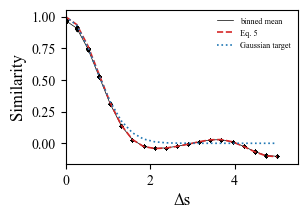

In [5]:
# Eq. 5: C(ds) = sum_i alpha_0,i^2 cos(ds * lambda_i,s), uniform coefficients 1/N.
# Because the context spectrum is Gaussian this is approximately exp(-scale^2 ds^2 / 2)
# -- the same factor of two as the spatial case in notebook 02.
ravelled = similarity_by_bin.reshape(len(CONTEXT_VALS), -1)
eq5 = np.array([np.sum((2 / N) * np.cos(ds * ev_s)) for ds in CONTEXT_VALS])
gaussian = np.exp(-(CONTEXT_SCALE**2) * CONTEXT_VALS**2 / 2)

plt.figure(figsize=(3, 2))
for i, ds in enumerate(CONTEXT_VALS):
    plt.scatter(ds * np.ones(ravelled.shape[-1]), ravelled[i], color="k", alpha=0.1, s=2)
plt.plot(CONTEXT_VALS, np.nanmean(ravelled, axis=-1), "k", linewidth=0.5, label="binned mean")
plt.plot(CONTEXT_VALS, eq5, "C3--", linewidth=1.2, label="Eq. 5")
plt.plot(CONTEXT_VALS, gaussian, "C0:", linewidth=1.2, label="Gaussian target")
plt.xlabel("Δs", fontsize=12)
plt.ylabel("Similarity", fontsize=12)
plt.xlim([0, 5.5])
plt.legend(fontsize=6, frameon=False)
plt.savefig(FIGURE_DIR / "Remapping_similarity.svg", dpi=300, transparent=True, bbox_inches="tight")
plt.savefig(FIGURE_DIR / "Remapping_similarity.png", dpi=300, transparent=True, bbox_inches="tight")

print(f"max |binned mean - Eq. 5|     = {np.nanmax(np.abs(np.nanmean(ravelled, axis=-1) - eq5)):.4f}")
print(f"rms |Eq. 5 - Gaussian target| = {np.sqrt(np.mean((eq5 - gaussian) ** 2)):.4f}")
print(f"  finite-N noise floor 1/sqrt(N/2) = {1 / np.sqrt(N // 2):.4f}")

100%|██████████| 500/500 [00:41<00:00, 12.02it/s]


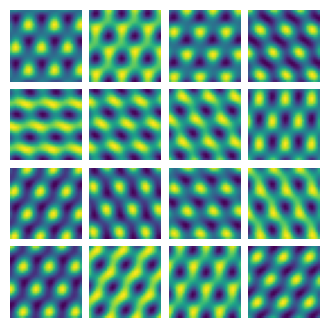

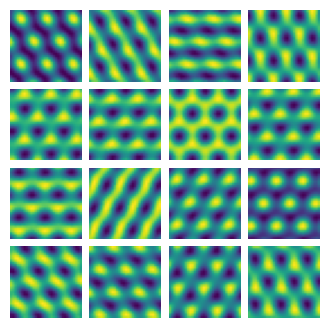

In [6]:
# Fig. 3, right: the same units at s = 0 and s = 5. The grid structure is intact in
# both; what changes is the absolute phase.
p_c2 = batch_inference(model, r_batch, p0, context=5.0)
ratemaps_c2 = compute_ratemaps(r[:, 0], r[:, 1], p_c2, bins=BINS)

for ratemaps, name in [(ratemaps_c1, "ratemap_c1"), (ratemaps_c2, "ratemaps_c2")]:
    fig, _ = ratemap_collage(ratemaps, rows=4, cols=4, figsize=(4, 4))
    fig.savefig(FIGURE_DIR / f"{name}.svg", dpi=300, transparent=True)
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=300, transparent=True)

max spread across 4 positions = 8.34e-06  (float32 noise; 0 in exact arithmetic)
max |unbinned - Eq. 5|        = 3.25e-06


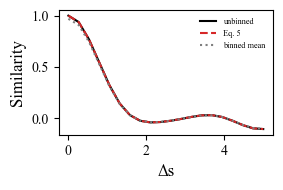

In [7]:
# The scatter above is binning error, not spatial structure. Evaluated at points rather
# than through ratemaps, the between-context similarity is the same everywhere, because
# the commuting skew-symmetric spatial generators cancel exactly.
probes = torch.tensor([[0.0, 0.0], [3.1, -2.4], [7.7, 5.2], [-9.0, 1.0]], dtype=torch.float32)

spreads, exact = [], []
for ds in CONTEXT_VALS:
    with torch.no_grad():
        a = model(probes, p0, context=0.0)
        b = model(probes, p0, context=float(ds))
    values = (a * b).sum(dim=1).numpy()
    spreads.append(values.max() - values.min())
    exact.append(values.mean())

print(f"max spread across 4 positions = {max(spreads):.2e}  (float32 noise; 0 in exact arithmetic)")
print(f"max |unbinned - Eq. 5|        = {np.max(np.abs(np.array(exact) - eq5)):.2e}")

plt.figure(figsize=(3, 2))
plt.plot(CONTEXT_VALS, exact, "k", label="unbinned")
plt.plot(CONTEXT_VALS, eq5, "C3--", label="Eq. 5")
plt.plot(CONTEXT_VALS, np.nanmean(ravelled, axis=-1), "C7:", label="binned mean")
plt.xlabel("Δs", fontsize=12)
plt.ylabel("Similarity", fontsize=12)
plt.legend(fontsize=6, frameon=False)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "Remapping_similarity_vs_eq5.svg", dpi=300, transparent=True)